# Experiment 2 – Quantum Teleportation using Qiskit

**Subject:** Computer Laboratory II – Quantum AI  
**Experiment:** 2  
**Aim:** To implement the Quantum Teleportation algorithm in Python using Qiskit and display the quantum circuit and measurement results.

## Objectives
1. Understand the Quantum Teleportation algorithm.
2. Create a three-qubit quantum circuit.
3. Create entanglement using a Bell pair.
4. Transfer an unknown quantum state using two classical measurement bits and quantum correction operations.

## What this notebook demonstrates
- Qubit 0 contains the state to be teleported. In this practical, it is initialized to `|1⟩` using an X gate.
- Qubits 1 and 2 form an entangled Bell pair.
- The teleportation operations are applied.
- The final state of qubit 2 is measured and the circuit and histogram are displayed.

> **Important:** Quantum teleportation does not physically move a particle or copy an unknown state. It transfers the quantum state using shared entanglement and two classical bits. The original state is consumed by the measurement process, consistent with the no-cloning theorem.

## Steps to run this notebook
1. Install **Python 3.10 or newer** (or use Anaconda).
2. Install Jupyter Notebook: `python -m pip install notebook`.
3. Open a terminal/Command Prompt in the folder where this notebook is saved.
4. Run: `jupyter notebook`
5. Open this file, then select **Kernel → Restart & Run All**.
6. Run the installation cell below if Qiskit is not already installed.
7. If the circuit drawing fails, ensure the notebook is running in an environment with Matplotlib installed.

**No IBM Quantum account or internet quantum computer is required.** This notebook uses a local simulator.


## 1. Install required libraries

Run this cell once in the notebook environment. If the packages were just installed, restart the kernel and run the notebook again.

The practical uses:
- `qiskit` – to create quantum circuits.
- `qiskit-aer` – to simulate the circuit locally.
- `matplotlib` – to draw the circuit and measurement histogram.
- `pylatexenc` – helps Qiskit render circuit diagrams using Matplotlib.


In [1]:
# Install the required Python packages.
# Run this cell once. In Jupyter, the %pip command installs into the
# same Python environment used by the current notebook kernel.

%pip install qiskit qiskit-aer matplotlib pylatexenc


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import the required libraries

We import `QuantumCircuit` to build the circuit, `AerSimulator` to execute it locally, `transpile` to prepare it for the simulator, and plotting functions to display the circuit and results.


In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

print("Libraries imported successfully.")


Libraries imported successfully.


## 3. Create the quantum circuit

We use **3 qubits** and **3 classical bits**.

| Qubit | Purpose |
|---|---|
| q0 | Holds the state that Sharanya wants to teleport |
| q1 | Sharanya's half of the entangled Bell pair |
| q2 | Kartik's half of the entangled Bell pair; receives the teleported state |

The classical bits store measurement outcomes. `c0` stores the measurement of `q0`, `c1` stores the measurement of `q1`, and `c2` stores the final measurement of `q2`.


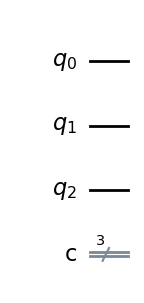

In [3]:
# Create a circuit with 3 quantum bits and 3 classical bits.
teleportation_circuit = QuantumCircuit(3, 3)

# Display the empty circuit.
teleportation_circuit.draw(output="mpl")


## 4. Prepare the state to be teleported

For this experiment, we prepare q0 in the state `|1⟩` by applying an X (NOT) gate.

- Initial state of q0: `|0⟩`
- After the X gate: `|1⟩`

The X gate changes `|0⟩` to `|1⟩`. This is a simple known test state. The teleportation protocol also works for an arbitrary single-qubit state.


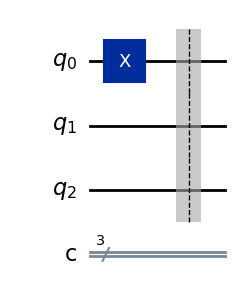

In [4]:
# Apply an X gate to q0 to prepare the state |1>.
teleportation_circuit.x(0)

# Barrier separates the state-preparation stage from later operations.
teleportation_circuit.barrier()

teleportation_circuit.draw(output="mpl")


## 5. Create entanglement (Bell pair) between q1 and q2

To create a Bell pair:

1. Apply a Hadamard (H) gate to q1. This places q1 into an equal superposition.
2. Apply a controlled-NOT (CX) gate with q1 as the control and q2 as the target.

The two qubits become entangled. Their joint state is:

\[
\frac{|00\rangle + |11\rangle}{\sqrt{2}}
\]

This means the pair must be described as one combined quantum state; the qubits are not independent.


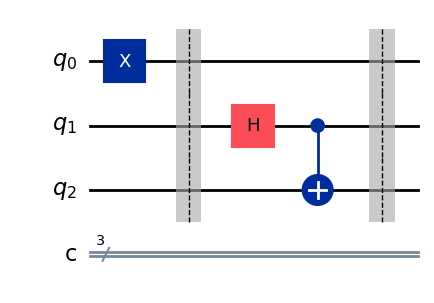

In [5]:
# Create a Bell pair shared between q1 and q2.
teleportation_circuit.h(1)
teleportation_circuit.cx(1, 2)

teleportation_circuit.barrier()
teleportation_circuit.draw(output="mpl")


## 6. Perform the Bell-state operations

Now combine the state in q0 with Sharanya's entangled qubit q1:

1. Apply CX with q0 as control and q1 as target.
2. Apply a Hadamard gate to q0.

These operations prepare the two qubits for measurement. Their measurement outcomes determine which correction is required on q2.


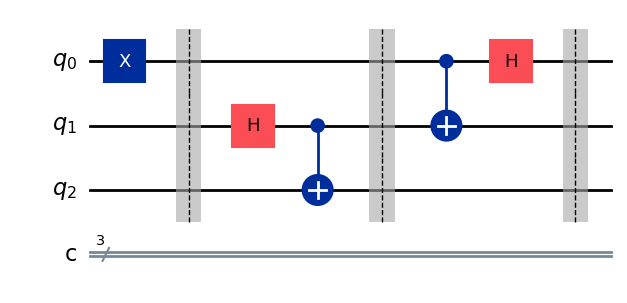

In [6]:
# Bell-state operations on q0 and q1.
teleportation_circuit.cx(0, 1)
teleportation_circuit.h(0)

teleportation_circuit.barrier()
teleportation_circuit.draw(output="mpl")


## 7. Apply the teleportation correction operations

In the usual measurement-and-classical-feed-forward description, the two measured bits determine the correction on q2:

| Measurement of q0, q1 | Correction on q2 |
|---|---|
| 00 | I (no correction) |
| 01 | X |
| 10 | Z |
| 11 | X and Z (equivalent to ZX up to a global phase) |

This notebook uses the **deferred-measurement equivalent**: it applies controlled-X and controlled-Z operations using q1 and q0 as controls, then measures all three qubits. This keeps the circuit compatible with a straightforward local simulator workflow while implementing the same teleportation correction logic.

- `CX(1, 2)` applies X to q2 when q1 is 1.
- `CZ(0, 2)` applies Z to q2 when q0 is 1.

The measurement of q0 and q1 is therefore placed after these correction gates. This is the coherent form of the correction stage.


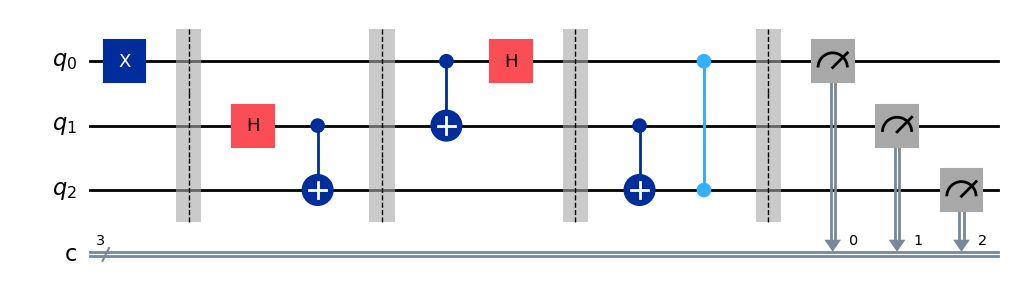

In [7]:
# Apply the correction operations coherently.
teleportation_circuit.cx(1, 2)
teleportation_circuit.cz(0, 2)

teleportation_circuit.barrier()

# Measure q0, q1 and q2 into classical bits c0, c1 and c2.
teleportation_circuit.measure([0, 1, 2], [0, 1, 2])

# Display the complete teleportation circuit.
teleportation_circuit.draw(output="mpl")


## 8. Simulate the quantum circuit

A simulator runs the quantum circuit on a classical computer. A **shot** is one run of the circuit. We use 1,000 shots so that we can observe the distribution of measurement outcomes.

`transpile` converts the circuit into instructions suitable for the selected simulator. `AerSimulator` performs the simulation.


In [8]:
# Create a local quantum simulator.
simulator = AerSimulator()

# Prepare the circuit for the simulator.
compiled_circuit = transpile(teleportation_circuit, simulator)

# Run the circuit 1000 times (shots).
job = simulator.run(compiled_circuit, shots=1000)

# Retrieve the measurement counts.
result = job.result()
counts = result.get_counts()

print("Measurement counts:")
print(counts)


Measurement counts:
{'100': 262, '111': 252, '110': 238, '101': 248}


## 9. Display the measurement histogram

The histogram shows how often each three-bit measurement result occurred.

For this experiment, q0 was initialized to `|1⟩`. After successful teleportation, q2 should also be measured as `1`. Because q0 and q1 are measured too, the histogram can contain multiple bit strings; the important check is that the **rightmost displayed bit** (classical bit c2 under Qiskit's usual count-string ordering) is `1` for the outcomes.

The exact counts can vary between simulator runs because measurement is probabilistic.


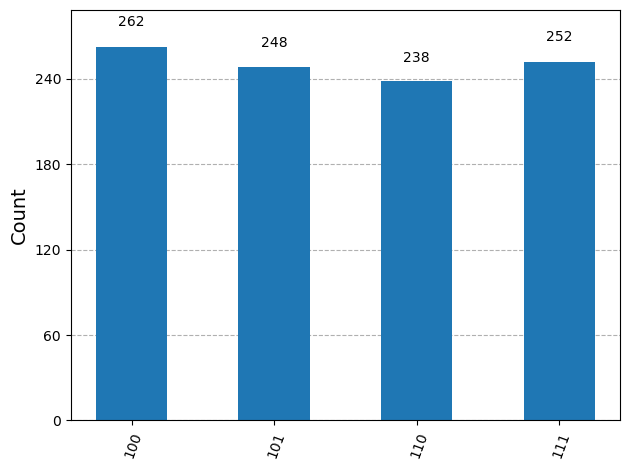

In [12]:
# Plot the measurement results.
# Import the required display functions
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt

# Generate the measurement histogram
histogram = plot_histogram(counts)

# Explicitly display the histogram in Jupyter Notebook
display(histogram)

# Close the figure after displaying it
plt.close(histogram)


## 10. Verify the teleportation result

Qiskit displays classical bit strings in reverse classical-bit order: `c2 c1 c0`. Therefore, the leftmost character in each displayed result corresponds to c2, which stores the measurement of q2.

For the input state `|1⟩`, the teleported output q2 should be `1`. The following cell checks the q2 bit across all observed outcomes.


In [10]:
# Check the q2 result from every measured bit string.
# Qiskit count strings are displayed as c2 c1 c0, so index 0 is c2.
total_shots = sum(counts.values())
q2_is_one = sum(number for bitstring, number in counts.items()
                if bitstring.replace(" ", "")[0] == "1")

print(f"Total shots: {total_shots}")
print(f"Shots where q2 = 1: {q2_is_one}")
print(f"Fraction where q2 = 1: {q2_is_one / total_shots:.3f}")

if q2_is_one == total_shots:
    print("Successful: q2 was measured as |1> in every shot.")
else:
    print("Check the circuit and bit ordering; q2 was not |1> in every shot.")


Total shots: 1000
Shots where q2 = 1: 1000
Fraction where q2 = 1: 1.000
Successful: q2 was measured as |1> in every shot.


## 11. Algorithm

1. Start.
2. Create a quantum circuit with three qubits and three classical bits.
3. Apply an X gate to q0 to prepare the state `|1⟩`.
4. Apply a Hadamard gate to q1.
5. Apply CX from q1 to q2 to create an entangled Bell pair.
6. Apply CX from q0 to q1.
7. Apply a Hadamard gate to q0.
8. Apply the controlled-X correction from q1 to q2.
9. Apply the controlled-Z correction from q0 to q2.
10. Measure q0, q1 and q2.
11. Run the circuit on the simulator and display the histogram.
12. Verify that q2 contains the teleported state `|1⟩`.
13. Stop.

## 12. Conclusion

The Quantum Teleportation algorithm was implemented in Python using Qiskit. A Bell pair was created using Hadamard and controlled-NOT gates. The Bell-state operations and correction gates transferred the prepared state from q0 to q2. The circuit was executed using a local Aer simulator, and the measurement results were displayed as a histogram.

**Outcome:** The quantum circuit for Quantum Teleportation was created and simulated successfully.


## 13. Viva questions and answers

**Q1. What is quantum teleportation?**  
Quantum teleportation is a protocol for transferring an unknown quantum state from one qubit to another using shared entanglement and two classical bits of communication.

**Q2. Does quantum teleportation move a physical particle?**  
No. It transfers the quantum state, not the physical particle itself.

**Q3. What is a qubit?**  
A qubit is the basic unit of quantum information. It can exist in a superposition of `|0⟩` and `|1⟩`.

**Q4. What is superposition?**  
Superposition is the ability of a quantum system to be in a combination of basis states until measurement.

**Q5. What is entanglement?**  
Entanglement is a quantum correlation in which the joint state of two or more qubits cannot be described as separate independent states.

**Q6. What is a Bell pair?**  
A Bell pair is a maximally entangled two-qubit state. In this experiment it is created as `(|00⟩ + |11⟩)/√2`.

**Q7. What does a Hadamard gate do?**  
It creates or transforms superposition. For example, it maps `|0⟩` to `(|0⟩ + |1⟩)/√2`.

**Q8. What does an X gate do?**  
It acts like a quantum NOT gate, swapping `|0⟩` and `|1⟩`.

**Q9. What is a CNOT or CX gate?**  
It flips the target qubit if the control qubit is `1`.

**Q10. What does a Z gate do?**  
It changes the phase of the `|1⟩` component while leaving `|0⟩` unchanged.

**Q11. Why are classical bits required?**  
The measurement outcomes are classical information that tells the receiver which correction operation is needed.

**Q12. How many classical bits are sent in quantum teleportation?**  
Two classical bits.

**Q13. What is the no-cloning theorem?**  
It states that an arbitrary unknown quantum state cannot be copied perfectly.

**Q14. What is the purpose of measurement?**  
Measurement obtains a classical result from a quantum state and generally changes or collapses the measured state.

**Q15. What is a shot in Qiskit?**  
A shot is one execution of the circuit. Multiple shots are used to build measurement statistics.

**Q16. What is Qiskit?**  
Qiskit is an open-source software framework for creating and running quantum circuits.

**Q17. What is AerSimulator?**  
AerSimulator is a Qiskit simulator backend that runs quantum circuits on a classical computer.

**Q18. Why do we use a histogram?**  
It visualizes how frequently each measurement result occurred.

**Q19. Which qubit contains the original state in this experiment?**  
q0.

**Q20. Which qubit should contain the teleported state?**  
q2.

**Q21. Why is q0 initialized with an X gate here?**  
To prepare a simple test input `|1⟩` instead of the default `|0⟩`.

**Q22. Does teleportation require an entangled pair?**  
Yes. Shared entanglement is an essential resource for the protocol.

**Q23. Can quantum teleportation send information faster than light?**  
No. The receiver needs the two classical bits, which cannot travel faster than light.

**Q24. What is the purpose of a barrier in a circuit?**  
A barrier visually separates stages of the circuit and can constrain compiler optimization across that point.

**Q25. What is the final expected result of this practical?**  
The output qubit q2 should be in the same state as the original input qubit q0. Since this practical prepares q0 as `|1⟩`, q2 should measure as `1`.
